# Bayesian Classification

This notebook explores Gaussian discriminant analysis, a multiclass Gaussian Naive Bayes implementation, and multinomial Naive Bayes for text classification.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

## Iris data and PCA

Project the four original Iris features onto two principal components using all 150 samples. This projection is intended for visualization, not held-out performance estimation.

In [5]:
iris = datasets.load_iris()
Xorig = iris.data      # 4D features
y = iris.target        # labels 0,1,2

# Project to 2D for visualization
pca = PCA(n_components=2)
X = pca.fit_transform(Xorig)

## Gaussian parameters and discriminant functions

Estimate class means and sample covariance matrices. The shared covariance is computed from pooled class-centered observations. LDA compares linear scores; QDA incorporates class-specific inverse covariance matrices and log determinants.

In [6]:
def estimate_gaussian_params(X_class):
    """Estimate the mean vector and covariance matrix of a class."""
    mu = X_class.mean(axis=0)
    Sigma = np.cov(X_class.T, bias=False)
    return mu, Sigma

def estimate_shared_covariance(X, y, class_indices):
    """Estimate a pooled covariance matrix for the given classes (LDA assumption)."""
    centered = []
    for c in class_indices:
        Xc = X[y == c]
        muc = Xc.mean(axis=0)
        centered.append(Xc - muc)
    centered = np.vstack(centered)
    Sigma = np.cov(centered.T, bias=False)
    return Sigma

def lda_discriminant(x, mu, Sigma_inv, prior):
    """
    Linear discriminant for Gaussian distributions with shared covariance:
    g(x) = xᵀ Σ⁻¹ μ - 0.5 μᵀ Σ⁻¹ μ + ln P(w)
    """
    x = np.asarray(x)
    term1 = x @ Sigma_inv @ mu
    term2 = -0.5 * mu @ Sigma_inv @ mu
    term3 = np.log(prior)
    return term1 + term2 + term3

def qda_discriminant(x, mu, Sigma, prior):
    """
    Quadratic discriminant for Gaussian class with its own covariance matrix.
    """
    x = np.asarray(x)
    Sigma_inv = np.linalg.inv(Sigma)
    sign, logdet = np.linalg.slogdet(Sigma)
    quad = -0.5 * ((x - mu) @ Sigma_inv @ (x - mu))
    const = -0.5 * logdet + np.log(prior)
    return quad + const

# Grid of points for visualizing decision regions
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]


## Linear discriminant analysis and class priors

For classes 1 and 2, the common covariance $\Sigma$ gives the score $g_i(x)=x^T\Sigma^{-1}\mu_i-\tfrac12\mu_i^T\Sigma^{-1}\mu_i+\log\pi_i$. Subtracting the scores yields $w^Tx+b=0$, where $w=\Sigma^{-1}(\mu_1-\mu_2)$ and $b=-\tfrac12(\mu_1^T\Sigma^{-1}\mu_1-\mu_2^T\Sigma^{-1}\mu_2)+\log(\pi_1/\pi_2)$. Changing priors from (0.5, 0.5) to (0.8, 0.2) adds $\log 4$ to the intercept without changing the orientation of the boundary; the region favoring class 1 expands.

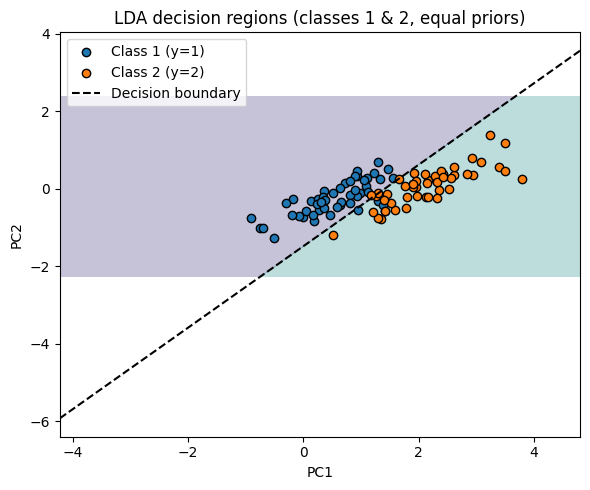

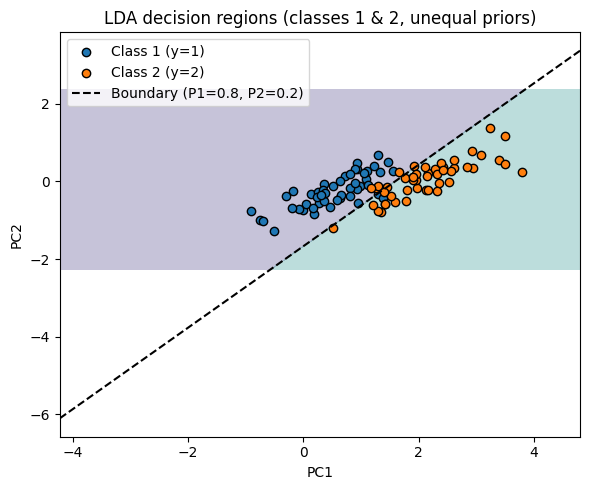

In [7]:

classes_12 = [1, 2]
X1 = X[y == 1]
X2 = X[y == 2]

# Estimate class parameters
mu1, Sigma1 = estimate_gaussian_params(X1)
mu2, Sigma2 = estimate_gaussian_params(X2)

# Shared covariance (LDA assumption)
Sigma_shared = estimate_shared_covariance(X, y, classes_12)
Sigma_inv = np.linalg.inv(Sigma_shared)

# Equal priors for the first part
prior1 = prior2 = 0.5

def discriminant_lda_two_classes(x, p1=prior1, p2=prior2):
    """Return discriminant values for the two classes."""
    g1 = lda_discriminant(x, mu1, Sigma_inv, p1)
    g2 = lda_discriminant(x, mu2, Sigma_inv, p2)
    return np.array([g1, g2])

# -------- (c) Decision regions for equal priors --------
g_vals = np.array([discriminant_lda_two_classes(pt) for pt in grid])
labels_grid = np.argmax(g_vals, axis=1).reshape(xx.shape)

# Decision boundary: wᵀ x + b = 0
delta_mu = mu1 - mu2
w = Sigma_inv @ delta_mu
const_equal = -0.5 * (mu1 @ Sigma_inv @ mu1 - mu2 @ Sigma_inv @ mu2)

xs = np.linspace(x_min, x_max, 400)
ys_equal = -(w[0] / w[1]) * xs - const_equal / w[1]

plt.figure(figsize=(6, 5))
plt.contourf(xx, yy, labels_grid, alpha=0.3, levels=[-0.5,0.5,1.5,2.5])
plt.scatter(X1[:, 0], X1[:, 1], label="Class 1 (y=1)", edgecolor='k')
plt.scatter(X2[:, 0], X2[:, 1], label="Class 2 (y=2)", edgecolor='k')
plt.plot(xs, ys_equal, 'k--', label="Decision boundary")
plt.legend()
plt.title("LDA decision regions (classes 1 & 2, equal priors)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.savefig("fig1_lda_equal_priors.png", dpi=200)
plt.show()

# -------- (e) Changing priors: P(class1)=0.8, P(class2)=0.2 --------
prior1_new, prior2_new = 0.8, 0.2

def discriminant_lda_two_classes_prior(x):
    return discriminant_lda_two_classes(x, p1=prior1_new, p2=prior2_new)

g_vals_new = np.array([discriminant_lda_two_classes_prior(pt) for pt in grid])
labels_grid_new = np.argmax(g_vals_new, axis=1).reshape(xx.shape)

# New boundary: only the constant term shifts
const_new = const_equal + np.log(prior1_new / prior2_new)
ys_new = -(w[0] / w[1]) * xs - const_new / w[1]

plt.figure(figsize=(6, 5))
plt.contourf(xx, yy, labels_grid_new, alpha=0.3, levels=[-0.5,0.5,1.5,2.5])
plt.scatter(X1[:, 0], X1[:, 1], label="Class 1 (y=1)", edgecolor='k')
plt.scatter(X2[:, 0], X2[:, 1], label="Class 2 (y=2)", edgecolor='k')
plt.plot(xs, ys_new, 'k--', label="Boundary (P1=0.8, P2=0.2)")
plt.legend()
plt.title("LDA decision regions (classes 1 & 2, unequal priors)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.savefig("fig2_lda_unequal_priors.png", dpi=200)
plt.show()

## Quadratic discriminant analysis

Fit a separate covariance matrix to each of the three classes. The score is $g_i(x)=-\tfrac12\log|\Sigma_i|-\tfrac12(x-\mu_i)^T\Sigma_i^{-1}(x-\mu_i)+\log\pi_i$. Unlike LDA, the quadratic terms generally do not cancel, allowing curved decision boundaries. Class priors are empirical.

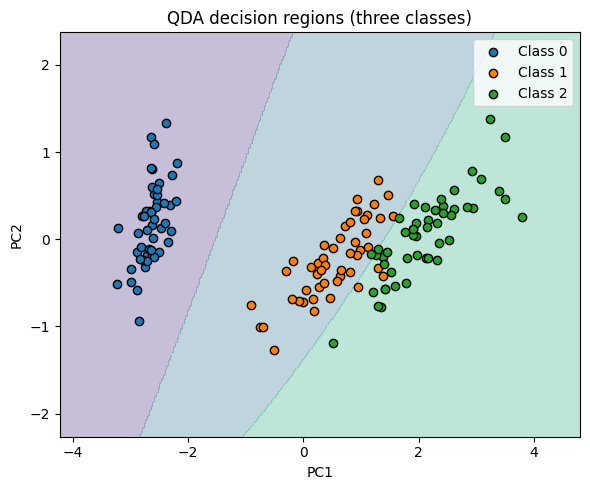

In [8]:
classes_all = [0, 1, 2]
mus = {}
Sigmas = {}
priors = {}

# Estimate parameters for each class
for c in classes_all:
    Xc = X[y == c]
    mus[c], Sigmas[c] = estimate_gaussian_params(Xc)
    priors[c] = Xc.shape[0] / X.shape[0]   # empirical priors

def discriminant_qda_all(x):
    """Return QDA discriminants for all classes."""
    return np.array([
        qda_discriminant(x, mus[c], Sigmas[c], priors[c])
        for c in classes_all
    ])

g_vals_qda = np.array([discriminant_qda_all(pt) for pt in grid])
labels_grid_qda = np.argmax(g_vals_qda, axis=1).reshape(xx.shape)

plt.figure(figsize=(6, 5))
plt.contourf(xx, yy, labels_grid_qda, alpha=0.3,
             levels=[-0.5,0.5,1.5,2.5,3.5])
for c in classes_all:
    Xc = X[y == c]
    plt.scatter(Xc[:, 0], Xc[:, 1], label=f"Class {c}", edgecolor='k')

plt.legend()
plt.title("QDA decision regions (three classes)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.savefig("fig3_qda_three_classes.png", dpi=200)
plt.show()

### Decision-region interpretation
The LDA boundary shifts parallel to itself as the prior changes, while the QDA regions exhibit curved boundaries because each class has its own covariance. These plots describe fitted geometry, not independent test accuracy. A rejection rule is a theoretical extension: with misclassification cost 1 and rejection cost $\lambda$, reject if $1-\max_i P(i\mid x)>\lambda$. Lower rejection cost expands the rejection region. The notebook does not execute an 80% split or rejection-region experiment.

## Gaussian Naive Bayes

Under conditional feature independence, the class posterior is proportional to the class prior times the product of univariate Gaussian likelihoods.

In [11]:
import numpy as np
from scipy.io import loadmat

### Class priors

Estimate each prior by the relative frequency of its class among the training labels, retaining a consistent class order.

In [12]:
def prior(y_train):
    """
    Compute class prior probabilities p(c) from training labels.

    Parameters
    ----------
    y_train : array of shape (n_samples,)
        Integer class labels.

    Returns
    -------
    p : array of shape (n_classes,)
        p[k] is the prior probability of class k (in sorted label order).
    classes : array of shape (n_classes,)
        The unique class labels, in the same order used for p, M, V.
    """
    y_train = np.asarray(y_train).ravel()
    classes, counts = np.unique(y_train, return_counts=True)
    p = counts / counts.sum()
    return p, classes


### Class-conditional feature distributions

Estimate each feature mean and sample variance (`ddof=1`) separately within each class. Add $10^{-9}$ to the variances for numerical stability.

In [13]:
def likelihood(x_train, y_train, classes):
    """
    Estimate Gaussian Naive Bayes parameters:
    class-conditional mean and variance for each feature.

    We assume:
        p(f_i | c) = N(f_i ; mu_{i,c}, sigma_{i,c}^2)

    Parameters
    ----------
    x_train : array of shape (n_samples, n_features)
        Training feature matrix.
    y_train : array of shape (n_samples,)
        Training labels.
    classes : array of unique class labels
        The same 'classes' returned by prior().

    Returns
    -------
    M : array of shape (n_features, n_classes)
        M[i, j] is the mean of feature i given class j.
    V : array of shape (n_features, n_classes)
        V[i, j] is the variance of feature i given class j.
    """
    x_train = np.asarray(x_train)
    y_train = np.asarray(y_train).ravel()

    n_samples, n_features = x_train.shape
    n_classes = len(classes)

    M = np.zeros((n_features, n_classes))
    V = np.zeros((n_features, n_classes))

    for idx, c in enumerate(classes):
        Xc = x_train[y_train == c]          # samples belonging to class c
        M[:, idx] = Xc.mean(axis=0)        # feature means for class c
        V[:, idx] = Xc.var(axis=0, ddof=1) # feature variances for class c

    # Numerical stability: avoid zero variances
    eps = 1e-9
    V = V + eps

    return M, V


### Classification in log space

Compare $\log p(c)+\sum_j\log p(x_j\mid c)$ and return the label corresponding to the highest score. Summing log likelihoods avoids underflow from multiplying many small probabilities.

In [14]:
def gaussian_log_likelihood(x, mu, var):
    """
    Compute log N(x ; mu, var) for each feature (1D Gaussian; summed over features).

    Parameters
    ----------
    x : array of shape (n_features,)
    mu : array of shape (n_features,)
    var : array of shape (n_features,)

    Returns
    -------
    log_prob : float
        Sum over features of log N(x_i ; mu_i, var_i).
    """
    # log N(x; mu, var) = -0.5 * [ log(2π var) + (x-mu)^2 / var ]  (element-wise)
    return -0.5 * (np.log(2.0 * np.pi * var).sum()
                   + ((x - mu) ** 2 / var).sum())


def naiveBayesClassify(x_test, M, V, p, classes):
    """
    Gaussian Naive Bayes classifier.

    For each test sample x and each class c, we compute:
        log p(c | x) ∝ log p(c) + sum_i log p(f_i | c)

    Parameters
    ----------
    x_test : array of shape (m_samples, n_features)
        Test feature matrix.
    M : array of shape (n_features, n_classes)
        Means per feature and class (from likelihood()).
    V : array of shape (n_features, n_classes)
        Variances per feature and class (from likelihood()).
    p : array of shape (n_classes,)
        Class prior probabilities.
    classes : array of shape (n_classes,)
        Class labels (same order as columns of M, V and entries of p).

    Returns
    -------
    t_pred : array of shape (m_samples,)
        Predicted class label for each test sample.
    """
    x_test = np.asarray(x_test)
    m_samples, n_features = x_test.shape
    n_features_M, n_classes = M.shape
    assert n_features == n_features_M

    t_pred = np.zeros(m_samples, dtype=classes.dtype)

    # Precompute log priors for efficiency
    log_p = np.log(p)

    for i in range(m_samples):
        x = x_test[i]
        log_post = np.zeros(n_classes)
        for j in range(n_classes):
            mu_j = M[:, j]
            var_j = V[:, j]
            # log p(x | c_j) under naive Gaussian assumption
            log_lik = gaussian_log_likelihood(x, mu_j, var_j)
            # log posterior up to additive constant
            log_post[j] = log_p[j] + log_lik
        # Choose class with maximum posterior
        best_idx = np.argmax(log_post)
        t_pred[i] = classes[best_idx]

    return t_pred



### Evaluation metrics

Accuracy measures the fraction of correct predictions; precision and recall for labels 1 and 5 use their corresponding true positive, predicted positive and actual positive counts.

In [15]:
def evaluate_metrics(y_test, y_pred, class_for_1=1, class_for_5=5):
    """
    Compute required evaluation metrics:

        - overall accuracy
        - precision for class 1
        - recall for class 1
        - precision for class 5
        - recall for class 5

    Parameters
    ----------
    y_test : array of shape (m_samples,)
        True test labels.
    y_pred : array of shape (m_samples,)
        Predicted labels.
    class_for_1 : int
        Label of the first class of interest (default 1).
    class_for_5 : int
        Label of the second class of interest (default 5).

    Returns
    -------
    metrics : dict
        Keys: 'accuracy', 'prec_1', 'recall_1', 'prec_5', 'recall_5'.
    """
    y_test = np.asarray(y_test).ravel()
    y_pred = np.asarray(y_pred).ravel()

    # Overall accuracy
    accuracy = (y_test == y_pred).mean()

    def precision_recall_for_class(c):
        """Compute precision and recall for a single class c."""
        true_pos = np.sum((y_pred == c) & (y_test == c))
        pred_pos = np.sum(y_pred == c)
        real_pos = np.sum(y_test == c)

        precision = true_pos / pred_pos if pred_pos > 0 else 0.0
        recall = true_pos / real_pos if real_pos > 0 else 0.0
        return precision, recall

    prec_1, recall_1 = precision_recall_for_class(class_for_1)
    prec_5, recall_5 = precision_recall_for_class(class_for_5)

    metrics = {
        "accuracy": accuracy,
        "prec_1": prec_1,
        "recall_1": recall_1,
        "prec_5": prec_5,
        "recall_5": recall_5,
    }
    return metrics

### Train and evaluate on the supplied splits

Load `../datasets/gaussian_bayes/guassianBayes.mat` containing `xTrain`, `yTrain`, `xTest` and `yTest`. Train on the training arrays and evaluate on the separate test arrays. Export the five metrics to `evaluation.txt`.

In [20]:
data = loadmat("../datasets/gaussian_bayes/guassianBayes.mat")

    # The variable names depend on the .mat file structure.
    # According to the assignment text they should be xTrain, yTrain, xTest, yTest.
xTrain = data["xTrain"]
yTrain = data["yTrain"]
xTest = data["xTest"]
yTest = data["yTest"]

    # Make sure labels are 1D arrays
yTrain = yTrain.ravel()
yTest = yTest.ravel()

    # ---- Training ----
p, classes = prior(yTrain)
M, V = likelihood(xTrain, yTrain, classes)

    # ---- Classification on test set ----
y_pred = naiveBayesClassify(xTest, M, V, p, classes)

    # ---- Evaluation ----
metrics = evaluate_metrics(yTest, y_pred, class_for_1=1, class_for_5=5)

print("Accuracy       :", metrics["accuracy"])
print("Precision (1)  :", metrics["prec_1"])
print("Recall (1)     :", metrics["recall_1"])
print("Precision (5)  :", metrics["prec_5"])
print("Recall (5)     :", metrics["recall_5"])

    # Write metrics to evaluation.txt, one per line, rounded to 3 decimals
with open("evaluation.txt", "w") as f:
        f.write(f"Accuracy: {metrics['accuracy']:.3f}\n")
        f.write(f"Precision for class 1: {metrics['prec_1']:.3f}\n")
        f.write(f"Recall for class 1: {metrics['recall_1']:.3f}\n")
        f.write(f"Precision for class 5: {metrics['prec_5']:.3f}\n")
        f.write(f"Recall for class 5: {metrics['recall_5']:.3f}\n")

Accuracy       : 0.8348623853211009
Precision (1)  : 0.9512195121951219
Recall (1)     : 0.975
Precision (5)  : 0.875
Recall (5)     : 0.7777777777777778


### Gaussian Naive Bayes results
| Metric | Value |
|---|---:|
| Accuracy | 83.486% |
| Class 1 precision | 95.122% |
| Class 1 recall | 97.500% |
| Class 5 precision | 87.500% |
| Class 5 recall | 77.778% |

Class 1 is recovered more reliably than class 5. In particular, class 5 recall is lower, indicating more missed actual positives proportionally. These two class-level results do not establish performance for all classes.

## Bag-of-Words Text Classification

Classify baseball and hockey newsgroup documents using word counts and multinomial Naive Bayes. Compare unsmoothed likelihoods with additive smoothing and investigate training sample size.

In [21]:
import numpy as np
import matplotlib.pyplot as plt

### Document-term matrices

Four CSV files contain the class-specific training and test matrices (50 documents per class per split, 5,822 vocabulary terms). Encode baseball as 0 and hockey as 1.

In [22]:
def load_bow_data(
    baseball_train_path="../datasets/bag_of_words/baseball_train_set.csv",
    hockey_train_path="../datasets/bag_of_words/hockey_train_set.csv",
    baseball_test_path="../datasets/bag_of_words/baseball_test_set.csv",
    hockey_test_path="../datasets/bag_of_words/hockey_test_set.csv",
):
    """
    Load bag-of-words CSV files for baseball and hockey.

    Each CSV is assumed to have:
        - rows = documents (posts)
        - columns = vocabulary terms
        - entries = word counts (integers)
    """
    # Use np.loadtxt or genfromtxt depending on file sizes / formats.
    # Here we assume pure numeric CSV.
    b_train = np.loadtxt(baseball_train_path, delimiter=",")
    h_train = np.loadtxt(hockey_train_path, delimiter=",")
    b_test = np.loadtxt(baseball_test_path, delimiter=",")
    h_test = np.loadtxt(hockey_test_path, delimiter=",")

    # Stack train and test sets, and create label arrays
    # Label convention: 0 = baseball, 1 = hockey
    X_train = np.vstack([b_train, h_train])
    y_train = np.concatenate([
        np.zeros(b_train.shape[0], dtype=int),
        np.ones(h_train.shape[0], dtype=int),
    ])

    X_test = np.vstack([b_test, h_test])
    y_test = np.concatenate([
        np.zeros(b_test.shape[0], dtype=int),
        np.ones(h_test.shape[0], dtype=int),
    ])

    return X_train, y_train, X_test, y_test


### Maximum likelihood and additive smoothing

For word count $n_{wc}$ in class $c$, the unsmoothed estimate is $n_{wc}/N_c$. The smoothed estimate is $(n_{wc}+\beta)/(N_c+\beta V)$, where $V$ is vocabulary size. This is the additive-pseudocount convention; it corresponds to a posterior mean under Dirichlet($\beta$), or an interior MAP formula under Dirichlet($\beta+1$).

In [23]:
def train_nb_mle(class_docs):
    """
    Train a multinomial Naive Bayes classifier using MLE.

    Parameters
    ----------
    class_docs : list of arrays
        class_docs[c] is an array of shape (n_docs_c, vocab_size)
        containing all training documents of class c.

    Returns
    -------
    pwc : array of shape (n_classes, vocab_size)
        pwc[c, w] is p(w | class=c) estimated by MLE.
    priors : array of shape (n_classes,)
        Class priors p(c). Here we use equal class priors as required.
    """
    n_classes = len(class_docs)
    vocab_size = class_docs[0].shape[1]

    pwc = np.zeros((n_classes, vocab_size))
    doc_counts = np.array([docs.shape[0] for docs in class_docs])

    # Equal class priors by assumption
    priors = np.ones(n_classes) / n_classes

    for c in range(n_classes):
        counts_c = class_docs[c].sum(axis=0)           # word counts in class c
        total_c = counts_c.sum()
        # MLE: p(w | c) = count_{w,c} / sum_v count_{v,c}
        # Some counts can be zero -> probabilities zero (no smoothing)
        pwc[c, :] = counts_c / total_c

    return pwc, priors


def train_nb_map(class_docs, beta):
    """
    Train a multinomial Naive Bayes classifier using MAP with symmetric
    Dirichlet prior parameter beta.

    Parameters
    ----------
    class_docs : list of arrays
        class_docs[c] is an array of shape (n_docs_c, vocab_size).
    beta : float
        Symmetric Dirichlet parameter. Each word gets 'beta' hallucinated counts.

    Returns
    -------
    pwc : array of shape (n_classes, vocab_size)
        pwc[c, w] is p(w | class=c) estimated by MAP.
    priors : array of shape (n_classes,)
        Class priors p(c), still taken to be equal.
    """
    n_classes = len(class_docs)
    vocab_size = class_docs[0].shape[1]

    pwc = np.zeros((n_classes, vocab_size))
    priors = np.ones(n_classes) / n_classes  # equal priors

    for c in range(n_classes):
        counts_c = class_docs[c].sum(axis=0)       # shape (V,)
        total_c = counts_c.sum()
        # MAP with symmetric Dirichlet(beta):
        # p_hat(w | c) = (count_{w,c} + beta) / (total_c + beta * V)
        pwc[c, :] = (counts_c + beta) / (total_c + beta * vocab_size)

    return pwc, priors

### Prediction and zero probabilities

The implemented log-score sums contributions only for words present in the document and having positive estimated probability. This avoids undefined products, but it also omits positive-count words with zero probability. Consequently, the unsmoothed baseline is not the exact multinomial likelihood (which would be zero for such a document). Ties select baseball.

In [24]:
def compute_log_likelihood(doc_counts, log_pwc_row):
    """
    Compute log P(x | c) for a single document under class c.

    We use the multinomial model:
        log P(x | c) = sum_w x_w log p(w | c)

    To avoid 0 * log 0 issues, we only sum over indices where x_w > 0
    and p(w | c) > 0.
    """
    doc_counts = np.asarray(doc_counts)
    # Mask indices where the document actually uses the word
    idx = doc_counts > 0
    # Among them, keep only words with non-zero probability
    idx = idx & (log_pwc_row > -np.inf)
    if not np.any(idx):
        return 0.0
    return (doc_counts[idx] * log_pwc_row[idx]).sum()


def predict_nb(X, pwc, priors):
    """
    Predict class labels for a set of documents using trained NB parameters.

    Parameters
    ----------
    X : array of shape (n_docs, vocab_size)
        Document-term matrix (word counts).
    pwc : array of shape (n_classes, vocab_size)
        Class-conditional probabilities from training.
    priors : array of shape (n_classes,)
        Class priors p(c).

    Returns
    -------
    y_pred : array of shape (n_docs,)
        Predicted class labels (0 = baseball, 1 = hockey).
    """
    n_docs, vocab_size = X.shape
    n_classes = pwc.shape[0]

    # Take logs once for numerical stability
    log_pwc = np.log(pwc, where=(pwc > 0), out=np.full_like(pwc, -np.inf))
    log_priors = np.log(priors)

    y_pred = np.zeros(n_docs, dtype=int)

    for i in range(n_docs):
        x = X[i]
        log_post = np.zeros(n_classes)
        for c in range(n_classes):
            log_lik = compute_log_likelihood(x, log_pwc[c])
            log_post[c] = log_priors[c] + log_lik
        # Break ties by choosing class 0 ("baseball") as required
        best = np.argmax(log_post)
        y_pred[i] = best

    return y_pred


### Evaluation helpers

Compute classification accuracy and the number of predictions assigned to each class.

In [25]:
def accuracy(y_true, y_pred):
    """Fraction of correctly classified samples."""
    return (y_true == y_pred).mean()


def class_counts(y_pred):
    """Return number of predictions for each class."""
    unique, counts = np.unique(y_pred, return_counts=True)
    return dict(zip(unique, counts))

### Prepare the training and test sets

Load both splits and group training documents by class for likelihood estimation.

In [26]:
# --- Load data ---
X_train, y_train, X_test, y_test = load_bow_data()

# Split training data by class
baseball_train = X_train[y_train == 0]
hockey_train  = X_train[y_train == 1]

class_docs_full = [baseball_train, hockey_train]

### Unsmoothed baseline

Evaluate the implemented maximum-likelihood scoring variant without additive pseudocounts.

In [28]:
pwc_mle, priors = train_nb_mle(class_docs_full)
y_pred_mle = predict_nb(X_test, pwc_mle, priors)

acc_mle = accuracy(y_test, y_pred_mle)
pred_counts_mle = class_counts(y_pred_mle)

print("=== Part (a): MLE Naive Bayes ===")
print("Test accuracy (MLE):", acc_mle)
print("Prediction counts (class 0=baseball, 1=hockey):", pred_counts_mle)


=== Part (a): MLE Naive Bayes ===
Test accuracy (MLE): 0.18
Prediction counts (class 0=baseball, 1=hockey): {np.int64(0): np.int64(64), np.int64(1): np.int64(36)}


### Baseline interpretation
The unsmoothed implementation achieves only **18% accuracy**, predicting 64 baseball and 36 hockey documents. Sparse word counts make zero-probability events common; the score masking also biases this baseline by dropping impossible observed events. Its poor result should not be generalized to every correct implementation of unsmoothed multinomial Naive Bayes.

### Effect of additive smoothing

Sweep $\beta$ from zero to 10 using all training documents. The logarithmic axis is appropriate for positive values; zero is reported in the numerical output but cannot be represented on a true log axis.

beta=      0  accuracy=0.1800
beta=  1e-08  accuracy=0.8700
beta=  1e-06  accuracy=0.8600
beta=  0.001  accuracy=0.8600
beta=   0.01  accuracy=0.8700
beta=    0.1  accuracy=0.8700
beta=      1  accuracy=0.7900
beta=      2  accuracy=0.6500
beta=      5  accuracy=0.5500
beta=     10  accuracy=0.5400


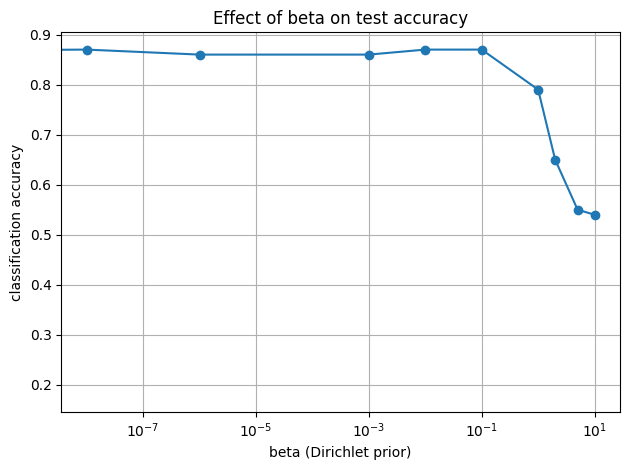

In [29]:
betas = [0, 1e-8, 1e-6, 1e-3, 1e-2, 1e-1, 1, 2, 5, 10]
accuracies_beta = []

for beta in betas:
        pwc_map, priors = train_nb_map(class_docs_full, beta)
        y_pred_map = predict_nb(X_test, pwc_map, priors)
        acc = accuracy(y_test, y_pred_map)
        accuracies_beta.append(acc)
        print(f"beta={beta:>7g}  accuracy={acc:.4f}")

# Plot beta vs accuracy (use log-scale on x-axis)
plt.figure()
plt.semilogx(betas, accuracies_beta, marker="o")
plt.xlabel("beta (Dirichlet prior)")
plt.ylabel("classification accuracy")
plt.title("Effect of beta on test accuracy")
plt.grid(True)
plt.tight_layout()
plt.savefig("accuracy_vs_beta.png", dpi=200)

### Smoothing results
Accuracy increases from 18% at zero smoothing to 87% at $\beta=10^{-8},0.01,0.1$. Strong smoothing reduces the discriminatory contrast between class-specific word probabilities: accuracy falls to 79%, 65%, 55% and 54% at $\beta=1,2,5,10$. The tested optimum is tied across three values; this is a descriptive comparison on the same test split.

### Effect of training-set size

Fix $\beta=0.1$ and use nested prefixes of 1–50 documents per class. Evaluate each fitted model on the same 100 test documents.

n= 1  accuracy=0.4600
n= 5  accuracy=0.5900
n=10  accuracy=0.7500
n=15  accuracy=0.6000
n=20  accuracy=0.7100
n=25  accuracy=0.8100
n=30  accuracy=0.8100
n=35  accuracy=0.8300
n=40  accuracy=0.8400
n=45  accuracy=0.8800
n=50  accuracy=0.8700


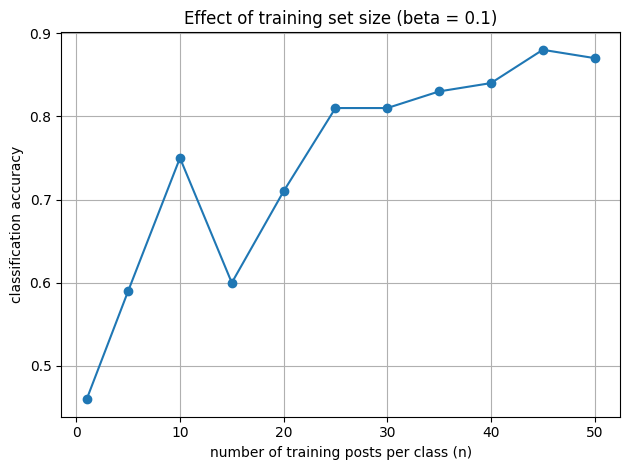

In [30]:
beta_fixed = 0.1
ns = [1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
accuracies_n = []

for n in ns:
        # Use the first n posts from each training set
        class_docs_n = [baseball_train[:n, :], hockey_train[:n, :]]
        pwc_map_n, priors_n = train_nb_map(class_docs_n, beta_fixed)
        y_pred_n = predict_nb(X_test, pwc_map_n, priors_n)
        acc_n = accuracy(y_test, y_pred_n)
        accuracies_n.append(acc_n)
        print(f"n={n:2d}  accuracy={acc_n:.4f}")

plt.figure()
plt.plot(ns, accuracies_n, marker="o")
plt.xlabel("number of training posts per class (n)")
plt.ylabel("classification accuracy")
plt.title(f"Effect of training set size (beta = {beta_fixed})")
plt.grid(True)
plt.tight_layout()
plt.savefig("accuracy_vs_n.png", dpi=200)

### Training size and conclusions
At one document per class, accuracy is 46%; at 25 it is 81%, and the best observed result is 88% at 45 documents per class. With all 50, accuracy is 87%. The trend is generally upward but not monotonic (e.g., 75% at 10 versus 60% at 15), reflecting the particular nested document prefixes. A separate validation split or repeated sampling would support a stronger comparison. See [analysis notes](docs/bayesian_classification.md).